# How much does smoking add to medical costs, and does it depend on BMI?

**Research question.** In this dataset of 1,338 insured adults, how much higher are smokers' annual medical charges after accounting for age, sex, BMI, children and region? And is the smoking penalty the same for everyone, or does it depend on body weight?

**Data.** [Medical Cost Personal Datasets](https://www.kaggle.com/datasets/mirichoi0218/insurance) (Kaggle), originally from *Machine Learning with R* by Brett Lantz. The book describes it as **simulated** using US Census demographics, so findings show patterns in this data, not real-world causal effects.

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from scipy import stats
import statsmodels.formula.api as smf
BG, FG, MUTED, A1, A2, A3, A4 = '#0F0E17', '#F4F1EA', '#9A93A8', '#E8577C', '#E8B86D', '#6D5EF5', '#38BDF8'
plt.rcParams.update({'figure.facecolor':BG,'axes.facecolor':BG,'axes.edgecolor':'#3a3747','axes.labelcolor':MUTED,
  'xtick.color':MUTED,'ytick.color':MUTED,'text.color':FG,'font.size':11,'axes.spines.top':False,'axes.spines.right':False,
  'axes.grid':True,'axes.axisbelow':True,'grid.color':'#24222f','savefig.facecolor':BG,'savefig.dpi':160,'legend.frameon':False})

In [2]:
df = pd.read_csv('insurance.csv')
print(df.shape, '| missing values:', df.isna().sum().sum(), '| duplicate rows:', df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
df['obese'] = (df['bmi'] >= 30).map({True:'BMI 30+', False:'BMI under 30'})
print(df.describe().round(1))
print(df['smoker'].value_counts(normalize=True).round(3))

(1338, 7) | missing values: 0 | duplicate rows: 1
          age     bmi  children  charges
count  1337.0  1337.0    1337.0   1337.0
mean     39.2    30.7       1.1  13279.1
std      14.0     6.1       1.2  12110.4
min      18.0    16.0       0.0   1121.9
25%      27.0    26.3       0.0   4746.3
50%      39.0    30.4       1.0   9386.2
75%      51.0    34.7       2.0  16657.7
max      64.0    53.1       5.0  63770.4
smoker
no     0.795
yes    0.205
Name: proportion, dtype: float64


## 1. The raw gap

In [3]:
raw = df.groupby('smoker')['charges'].agg(['mean','median','size']).round(0)
print(raw)
print(f"Median smoker charges are {raw.loc['yes','median']/raw.loc['no','median']:.1f}x non-smokers'")
u, p = stats.mannwhitneyu(df.loc[df.smoker=='yes','charges'], df.loc[df.smoker=='no','charges'])
print(f'Mann-Whitney U test: p={p:.2g}')

           mean   median  size
smoker                        
no       8441.0   7346.0  1063
yes     32050.0  34456.0   274
Median smoker charges are 4.7x non-smokers'
Mann-Whitney U test: p=5.7e-130


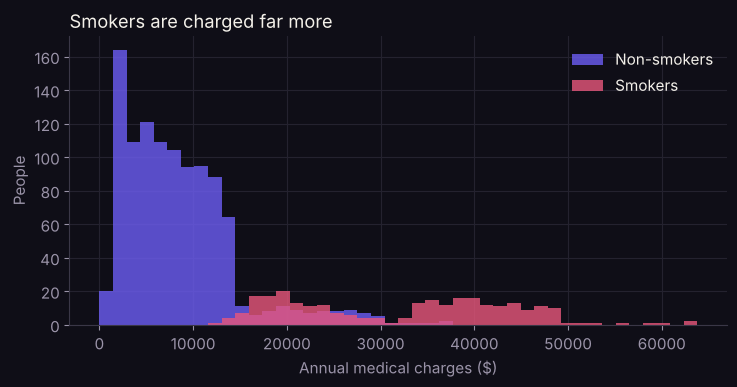

In [4]:
fig, ax = plt.subplots(figsize=(7.5,4))
bins = np.linspace(0, df['charges'].max(), 45)
ax.hist(df.loc[df.smoker=='no','charges'], bins=bins, color=A3, alpha=0.8, label='Non-smokers')
ax.hist(df.loc[df.smoker=='yes','charges'], bins=bins, color=A1, alpha=0.8, label='Smokers')
ax.set_xlabel('Annual medical charges ($)'); ax.set_ylabel('People'); ax.legend()
ax.set_title('Smokers are charged far more', loc='left', color=FG)
fig.tight_layout(); fig.savefig('figures/01_charges_by_smoking.png'); plt.show()

## 2. Does the smoking penalty depend on BMI?

In [5]:
cell = df.groupby(['smoker','obese'])['charges'].agg(['median','mean','size']).round(0)
print(cell)
for o in ['BMI under 30','BMI 30+']:
    s, n = df[(df.smoker=='yes')&(df.obese==o)]['charges'], df[(df.smoker=='no')&(df.obese==o)]['charges']
    print(f'{o}: smokers pay ${s.mean()-n.mean():,.0f} more on average')

                      median     mean  size
smoker obese                               
no     BMI 30+        8084.0   8856.0   561
       BMI under 30   6762.0   7977.0   502
yes    BMI 30+       40904.0  41558.0   145
       BMI under 30  20167.0  21363.0   129
BMI under 30: smokers pay $13,386 more on average
BMI 30+: smokers pay $32,702 more on average


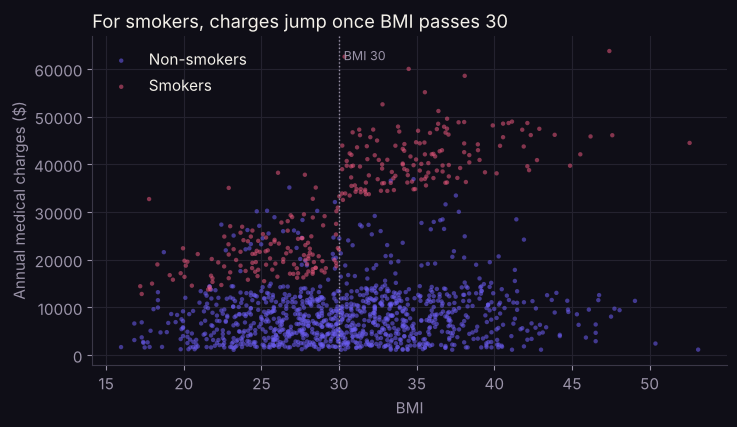

In [6]:
fig, ax = plt.subplots(figsize=(7.5,4.4))
for sm, c in [('no',A3),('yes',A1)]:
    s = df[df.smoker==sm]
    ax.scatter(s['bmi'], s['charges'], s=10, alpha=0.55, color=c, edgecolor='none', label='Smokers' if sm=='yes' else 'Non-smokers')
ax.axvline(30, color=MUTED, ls=':', lw=1); ax.text(30.3, df['charges'].max()*0.97, 'BMI 30', color=MUTED, fontsize=9)
ax.set_xlabel('BMI'); ax.set_ylabel('Annual medical charges ($)'); ax.legend(loc='upper left')
ax.set_title('For smokers, charges jump once BMI passes 30', loc='left', color=FG)
fig.tight_layout(); fig.savefig('figures/02_bmi_by_smoking.png'); plt.show()

## 3. Regression: separating smoking from age, BMI and the rest

In [7]:
m1 = smf.ols('charges ~ age + C(sex) + bmi + children + C(smoker) + C(region)', data=df).fit()
print(m1.summary().tables[1])

                             coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------
Intercept              -1.194e+04    988.227    -12.079      0.000   -1.39e+04   -9997.900
C(sex)[T.male]          -129.4815    333.195     -0.389      0.698    -783.128     524.165
C(smoker)[T.yes]        2.385e+04    413.348     57.693      0.000     2.3e+04    2.47e+04
C(region)[T.northwest]  -349.2265    476.824     -0.732      0.464   -1284.637     586.183
C(region)[T.southeast] -1035.2656    478.867     -2.162      0.031   -1974.684     -95.847
C(region)[T.southwest]  -960.0814    478.106     -2.008      0.045   -1898.007     -22.156
age                      256.7646     11.912     21.555      0.000     233.396     280.133
bmi                      339.2504     28.611     11.857      0.000     283.122     395.379
children                 474.8205    137.897      3.443      0.001     204.301     745.340

In [8]:
# Add a smoking x BMI 30+ interaction: does the smoking penalty differ by BMI?
df['smoker_y'] = (df.smoker=='yes').astype(int); df['obese30'] = (df.bmi>=30).astype(int)
m3 = smf.ols('charges ~ age + C(sex) + children + C(region) + smoker_y + obese30 + smoker_y:obese30', data=df).fit()
pen_under = m3.params['smoker_y']; pen_over = pen_under + m3.params['smoker_y:obese30']
ci = m3.conf_int()
print(f'R2 = {m3.rsquared:.3f} (additive model: {m1.rsquared:.3f})')
print(f'Smoking penalty, BMI under 30: ${pen_under:,.0f}  (95% CI {ci.loc["smoker_y",0]:,.0f} to {ci.loc["smoker_y",1]:,.0f})')
print(f'Extra penalty for smokers with BMI 30+: ${m3.params["smoker_y:obese30"]:,.0f}  (95% CI {ci.loc["smoker_y:obese30",0]:,.0f} to {ci.loc["smoker_y:obese30",1]:,.0f}), p={m3.pvalues["smoker_y:obese30"]:.2g}')
print(f'Smoking penalty, BMI 30+: ${pen_over:,.0f}')
print(f'BMI 30+ effect for NON-smokers: ${m3.params["obese30"]:,.0f}, p={m3.pvalues["obese30"]:.2g}')
print(f'Each extra year of age: ${m3.params["age"]:,.0f}')

R2 = 0.863 (additive model: 0.751)
Smoking penalty, BMI under 30: $13,360  (95% CI 12,486 to 14,234)
Extra penalty for smokers with BMI 30+: $19,855  (95% CI 18,653 to 21,056), p=2.6e-170
Smoking penalty, BMI 30+: $33,215
BMI 30+ effect for NON-smokers: $204, p=0.47
Each extra year of age: $265


In [9]:
# Bootstrap check on the two penalties (2,000 resamples)
rng = np.random.default_rng(42); boot = []
for _ in range(2000):
    b = df.iloc[rng.integers(0, len(df), len(df))]
    f = smf.ols('charges ~ age + C(sex) + children + C(region) + smoker_y + obese30 + smoker_y:obese30', data=b).fit()
    boot.append((f.params['smoker_y'], f.params['smoker_y'] + f.params['smoker_y:obese30']))
boot = np.array(boot)
lo, hi = np.percentile(boot, [2.5, 97.5], axis=0)
print(f'Bootstrap 95% CI, penalty BMI under 30: ${lo[0]:,.0f} to ${hi[0]:,.0f}')
print(f'Bootstrap 95% CI, penalty BMI 30+: ${lo[1]:,.0f} to ${hi[1]:,.0f}')

Bootstrap 95% CI, penalty BMI under 30: $12,600 to $14,132
Bootstrap 95% CI, penalty BMI 30+: $32,453 to $34,040


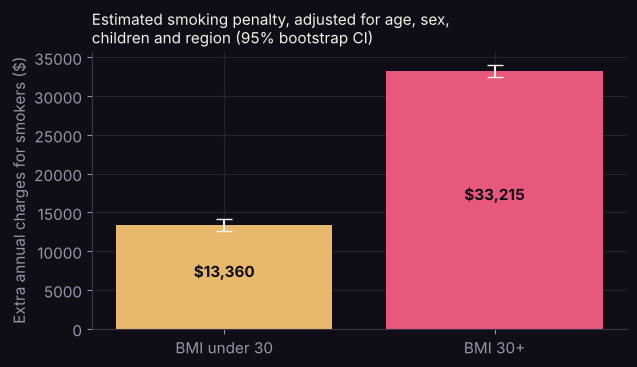

In [10]:
fig, ax = plt.subplots(figsize=(6.5,3.8))
vals = [pen_under, pen_over]; errs = np.array([[pen_under-lo[0], pen_over-lo[1]],[hi[0]-pen_under, hi[1]-pen_over]])
ax.bar(['BMI under 30','BMI 30+'], vals, color=[A2, A1], yerr=errs, capsize=6, ecolor=FG)
for i,v in enumerate(vals): ax.text(i, v/2, f'${v:,.0f}', ha='center', color='#0F0E17', fontweight='bold')
ax.set_ylabel('Extra annual charges for smokers ($)')
ax.set_title('Estimated smoking penalty, adjusted for age, sex,\nchildren and region (95% bootstrap CI)', loc='left', color=FG, fontsize=11)
fig.tight_layout(); fig.savefig('figures/03_smoking_penalty.png'); plt.show()

## Limitations

- **Simulated data.** The source book describes the dataset as simulated from US Census figures, so it can't establish real-world effects.
- **Charges, not health.** These are amounts billed, which reflect pricing as well as illness.
- **BMI 30 threshold.** A simple cut-off chosen for readability; BMI itself is a rough measure of body fat.
- **No information on** medical history, income or insurance plan, all of which affect charges.